# PyTorch для табличной регрессии: минуты доставки «Зерна»

Блокнот к уроку «PyTorch: то же самое, но в промышленном масштабе» главы 11. В браузере PyTorch не запускается, поэтому полный цикл — здесь, на своём компьютере:

- признаки из pandas → тензоры float32;
- сеть классом `nn.Module` с инициализацией He, по желанию — dropout и BatchNorm;
- smoke-test перед обучением;
- функция `train_loop`: мини-батчи, ранняя остановка по валидации, обрезка градиента;
- журнал экспериментов в DataFrame и честное сравнение с бустингом.

**Как запустить.** Блокнот лежит в папке курса `notebooks/extra/`, файл `deliveries.csv` он находит сам — ищет папку `data` выше по дереву папок. Нужны библиотеки из `notebooks/requirements.txt` и PyTorch: `uv add torch` (или `pip install torch`). Видеокарта не нужна: на процессоре блокнот выполняется за несколько минут, а если есть CUDA или Apple MPS, код переключится на них сам. Выполняйте сверху вниз (Restart & Run All).

Числа в текстовых выводах получены на процессоре. На другом компьютере или другой версии PyTorch MAE может отличаться в сотых, а время обучения — в разы: сравнивайте время моделей между собой на своей машине, а не с нашими цифрами.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

RANDOM_STATE = 42
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
torch.manual_seed(RANDOM_STATE)
DATA = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "deliveries.csv").exists())

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)
print("данные:", DATA.name, "| устройство:", device)

pandas 3.0.5 | scikit-learn 1.9.1 | torch 2.14.1+cu130
данные: data | устройство: cpu


## 1. Цель

Курьерская доставка «Зерна» обещает гостю время, и каждая лишняя минута опоздания — повод для низкой оценки. Модель прогноза фактического времени доставки (`actual_min`) нужна, чтобы обещать честно.

**Вопрос блокнота:** может ли небольшая нейросеть на PyTorch предсказывать время доставки точнее градиентного бустинга на тех же признаках?

**Метрика** — MAE в минутах: на сколько в среднем ошибается прогноз. Модели и их настройки выбираем по валидационной выборке, тестовую смотрим в конце и только для итогового сравнения.

## 2. Данные

Признаки — те же, что в уроке про MLP: расстояние, число позиций, час заказа, тип курьера, погода и кофейня. Категории превращаем в столбцы 0/1, доставки с явно ошибочным временем (вне 1–299 минут) убираем.

In [2]:
d = pd.read_csv(DATA / "deliveries.csv", parse_dates=["created"])
ok = d[d["actual_min"].between(1, 299)].copy()
ok["hour"] = ok["created"].dt.hour
X = pd.get_dummies(ok[["distance_km", "items", "hour", "courier", "weather", "shop_id"]], dtype=int)
y = ok["actual_min"]
print("доставок всего:", len(d), "| после чистки:", len(ok), "| признаков:", X.shape[1])
X.head(3)

доставок всего: 1877 | после чистки: 1841 | признаков: 16


,distance_km,items,hour,courier_авто,courier_вело,courier_пеший,weather_дождь,weather_облачно,weather_снег,weather_ясно,shop_id_KZN-1,shop_id_KZN-2,shop_id_PRM-1,shop_id_PRM-2,shop_id_TMN-1,shop_id_UFA-1
0,1.1,6,11,0,0,1,0,0,0,1,0,0,0,1,0,0
1,4.2,5,13,1,0,0,0,1,0,0,0,0,1,0,0,0
2,4.6,2,13,0,1,0,0,0,0,1,0,0,1,0,0,0


Делим на обучение, валидацию и тест. Тест — те же 25 %, что в уроке про MLP (`random_state=42`); из оставшегося 20 % уходит в валидацию — по ней работает ранняя остановка и выбирается лучшая сеть.

Сети нужны признаки в одном масштабе, поэтому `StandardScaler` обучаем только на обучающей части. Цель тоже стандартизуем: сеть учится предсказывать «на сколько отклонений от среднего», а в минуты прогноз переводим обратно умножением на `y_std` и прибавлением `y_mean`. Тензоры — float32: этого ждут слои PyTorch.

In [3]:
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)
y_mean, y_std = y_train.mean(), y_train.std()

def to_tensors(X_part, y_part):
    xt = torch.tensor(scaler.transform(X_part), dtype=torch.float32)
    yt = torch.tensor(((y_part - y_mean) / y_std).to_numpy(), dtype=torch.float32)
    return xt, yt

Xt_train, yt_train = to_tensors(X_train, y_train)
Xt_val, yt_val = to_tensors(X_val, y_val)
Xt_test, yt_test = to_tensors(X_test, y_test)
print("обучение:", tuple(Xt_train.shape), "| валидация:", tuple(Xt_val.shape), "| тест:", tuple(Xt_test.shape))
print(f"цель: среднее {y_mean:.1f} мин, отклонение {y_std:.1f} мин; dtype {Xt_train.dtype}")

обучение: (1104, 16) | валидация: (276, 16) | тест: (461, 16)
цель: среднее 34.4 мин, отклонение 11.1 мин; dtype torch.float32


**Вывод по данным.** После чистки осталось 1841 доставка и 16 признаков. На обучение — 1104 доставки, на валидацию — 276, на тест — 461. Средняя доставка длится 34.4 минуты при отклонении 11.1 минуты: это масштаб, в котором стоит читать MAE.

## 3. Ориентиры

Прежде чем учить сеть, нужны точки отсчёта: константа (медиана обучающей выборки), линейная регрессия и бустинг `HistGradientBoostingRegressor`. Все результаты — и ориентиры, и сети — пишем в один журнал `results` функцией `log_result`: модель, MAE на валидации и тесте, время обучения и прогноза. Время прогноза меряем лучшим из пяти запусков — первый запуск часто медленнее из-за «прогрева».

In [4]:
results = []

def best_time(fn, repeat=5):
    """Лучшее время из нескольких запусков, в секундах: первый запуск часто медленнее из-за прогрева."""
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)

def log_result(model_name, mae_val, mae_test, fit_sec, predict_sec, note=""):
    results.append({"модель": model_name, "MAE вал.": round(mae_val, 2), "MAE тест": round(mae_test, 2),
                    "обучение, с": round(fit_sec, 2), "прогноз, мс": round(predict_sec * 1000, 1), "заметка": note})

const_pred = np.full(len(y_test), y_train.median())
log_result("медиана обучения", mean_absolute_error(y_val, np.full(len(y_val), y_train.median())),
           mean_absolute_error(y_test, const_pred), 0.0, 0.0, "ориентир «ничего не знаем»")

for name, model in [("линейная регрессия", LinearRegression()),
                    ("бустинг HGB", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]:
    start = time.perf_counter()
    model.fit(scaler.transform(X_train), y_train)
    fit_sec = time.perf_counter() - start
    X_test_s = scaler.transform(X_test)
    predict_sec = best_time(lambda: model.predict(X_test_s))
    log_result(name, mean_absolute_error(y_val, model.predict(scaler.transform(X_val))),
               mean_absolute_error(y_test, model.predict(X_test_s)), fit_sec, predict_sec)

pd.DataFrame(results)

,модель,MAE вал.,MAE тест,"обучение, с","прогноз, мс",заметка
0,медиана обучения,8.03,8.15,0.00,0.0,ориентир «ничего не знаем»
1,линейная регрессия,5.46,5.52,0.05,0.1,
2,бустинг HGB,4.40,4.27,0.79,13.1,


**Вывод по ориентирам.** Прогноз «всем — медиану» ошибается в среднем на 8.03 минуты (валидация). Линейная регрессия снижает ошибку до 5.46, бустинг — до 4.40. Планка для сети — бустинг: чтобы сеть имела смысл, она должна опуститься ниже 4.40 на валидации.

## 4. Сеть: класс, smoke-test, цикл обучения

`DeliveryNet` — класс-наследник `nn.Module`. Скрытые слои собираются в цикле по кортежу `hidden`, после каждого линейного слоя по желанию — `BatchNorm1d`, затем ReLU и по желанию dropout. Веса скрытых слоёв — по He (`kaiming_normal_`), выходной слой оставлен со стандартной инициализацией PyTorch: так стартовые прогнозы небольшие. Слои сложены в `nn.Sequential`, а не в обычный список — иначе `model.parameters()` их бы не увидел.

In [5]:
class DeliveryNet(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), p_drop=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.body = nn.Sequential(*layers)
        for m in self.body[:-1]:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.body(x).squeeze(1)

model = DeliveryNet(Xt_train.shape[1])
print(model)
print("параметров:", sum(p.numel() for p in model.parameters()))

DeliveryNet(
  (body): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
параметров: 3201


**Smoke-test** — три быстрые проверки до долгого обучения: форма выхода и отсутствие `nan`, разумная стартовая потеря и способность «зазубрить» 32 доставки. Цель стандартизована, поэтому MSE прогноза «всегда среднее» равна 1, и стартовая потеря должна быть того же порядка.

In [6]:
torch.manual_seed(RANDOM_STATE)
model = DeliveryNet(Xt_train.shape[1]).to(device)
loss_fn = nn.MSELoss()
xb, yb = Xt_train[:32].to(device), yt_train[:32].to(device)

out = model(xb)
assert out.shape == yb.shape, (out.shape, yb.shape)
assert not torch.isnan(out).any()
print("1) форма выхода:", tuple(out.shape), "— как у ответа")
print("2) стартовая MSE в стандартных единицах:", round(loss_fn(out, yb).item(), 3), "(ориентир — порядка 1)")

opt = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for _ in range(300):
    opt.zero_grad()
    loss = loss_fn(model(xb), yb)
    loss.backward()
    opt.step()
print(f"3) MSE на 32 доставках после 300 шагов: {loss.item():.1e} — сеть умеет «зазубрить» маленький кусок")

1) форма выхода: (32,) — как у ответа
2) стартовая MSE в стандартных единицах: 1.159 (ориентир — порядка 1)


3) MSE на 32 доставках после 300 шагов: 3.5e-14 — сеть умеет «зазубрить» маленький кусок


Стартовая MSE — 1.159, порядок ожидаемый. За 300 шагов на 32 доставках потеря упала практически до нуля: прямой проход, градиенты и шаг оптимизатора работают. Можно переходить к настоящему обучению.

`train_loop` — цикл обучения из урока:

- `DataLoader` нарезает обучающую выборку на перемешанные батчи по 64 (генератор с `RANDOM_STATE` — чтобы порядок повторялся); `drop_last=True` выбрасывает короткий последний батч — с BatchNorm батч из одного объекта упал бы;
- на каждом батче: `zero_grad` → прогноз → MSE → `backward` → обрезка градиента по норме 5 → `step`;
- после эпохи — MAE на валидации в минутах (`evaluate_mae` переключает сеть в `eval()` и считает без графа вычислений);
- ранняя остановка: если 15 эпох подряд MAE на валидации не улучшается, обучение прекращается, а в модель возвращаются веса лучшей эпохи.

In [7]:
def evaluate_mae(model, X_t, y_true):
    model.eval()
    with torch.no_grad():
        pred = model(X_t.to(device)).cpu().numpy() * y_std + y_mean
    return mean_absolute_error(y_true, pred), pred


def train_loop(model, epochs=200, lr=1e-3, weight_decay=0.0, batch_size=64, patience=15):
    """Обучает модель мини-батчами с ранней остановкой по MAE на валидации.

    Возвращает историю по эпохам (DataFrame) и номер лучшей эпохи;
    в модели остаются веса лучшей эпохи.
    """
    gen = torch.Generator().manual_seed(RANDOM_STATE)
    loader = DataLoader(TensorDataset(Xt_train, yt_train), batch_size=batch_size, shuffle=True,
                        generator=gen, drop_last=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    history, best_mae, best_epoch, best_state = [], np.inf, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            opt.step()
            total += loss.item() * len(yb)
        val_mae, _ = evaluate_mae(model, Xt_val, y_val)
        history.append({"эпоха": epoch, "MSE обуч.": total / (len(loader) * batch_size), "MAE вал.": val_mae})
        if val_mae < best_mae - 1e-4:
            best_mae, best_epoch = val_mae, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch

**Вывод по разделу.** Сеть из двух скрытых слоёв (64 и 32 нейрона) — 3201 параметр. Smoke-test пройден. `train_loop` возвращает историю по эпохам — из неё строятся кривые обучения — и номер лучшей эпохи.

## 5. Эксперименты и журнал

Пять вариантов сети: базовая 64-32, с dropout 0.2, с BatchNorm, пошире (128-64) с L2-регуляризацией через `weight_decay` и маленькая с одним слоем из 32 нейронов. У каждого эксперимента один и тот же `torch.manual_seed`, поэтому различия — от настроек, а не от удачи стартовых весов. Результаты дописываются в тот же журнал, что и ориентиры.

Журнал — обычный DataFrame: его можно сортировать, фильтровать и сохранить рядом с блокнотом (`log.to_csv("experiments.csv", index=False)`), чтобы сравнивать запуски разных дней.

In [8]:
experiments = {
    "64-32": dict(hidden=(64, 32)),
    "64-32, dropout 0.2": dict(hidden=(64, 32), p_drop=0.2),
    "64-32, BatchNorm": dict(hidden=(64, 32), batchnorm=True),
    "128-64, wd 1e-4": dict(hidden=(128, 64), weight_decay=1e-4),
    "32": dict(hidden=(32,)),
}
histories, models = {}, {}
for name, cfg in experiments.items():
    cfg = dict(cfg)
    wd = cfg.pop("weight_decay", 0.0)
    torch.manual_seed(RANDOM_STATE)
    net = DeliveryNet(Xt_train.shape[1], **cfg).to(device)
    start = time.perf_counter()
    hist, best_epoch = train_loop(net, weight_decay=wd)
    fit_sec = time.perf_counter() - start
    mae_val, _ = evaluate_mae(net, Xt_val, y_val)
    mae_test, _ = evaluate_mae(net, Xt_test, y_test)
    predict_sec = best_time(lambda: evaluate_mae(net, Xt_test, y_test))
    log_result(f"сеть {name}", mae_val, mae_test, fit_sec, predict_sec,
               f"эпох {len(hist)}, лучшая {best_epoch}")
    histories[name], models[name] = hist, net

log = pd.DataFrame(results)
log

,модель,MAE вал.,MAE тест,"обучение, с","прогноз, мс",заметка
0,медиана обучения,8.03,8.15,0.00,0.0,ориентир «ничего не знаем»
1,линейная регрессия,5.46,5.52,0.05,0.1,
2,бустинг HGB,4.40,4.27,0.79,13.1,
3,сеть 64-32,5.08,4.84,12.87,0.8,"эпох 51, лучшая 36"
4,"сеть 64-32, dropout 0.2",4.92,4.86,32.75,0.8,"эпох 77, лучшая 62"
5,"сеть 64-32, BatchNorm",5.01,4.91,9.50,0.9,"эпох 35, лучшая 20"
6,"сеть 128-64, wd 1e-4",5.09,4.79,4.78,1.2,"эпох 35, лучшая 20"
7,сеть 32,5.03,4.74,19.24,0.6,"эпох 141, лучшая 126"


Как читать журнал: «эпох» — сколько эпох прошло до ранней остановки, «лучшая» — эпоха, веса которой остались в модели. Все сети остановились задолго до лимита в 200 эпох — ранняя остановка сработала. Время обучения на загруженной машине «шумное»; сравнивайте его у себя.

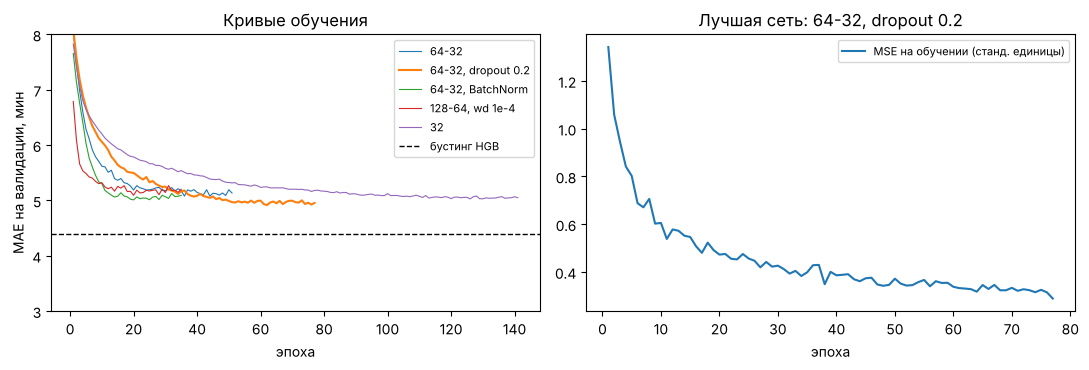

лучшая сеть по валидации: 64-32, dropout 0.2


In [9]:
nets = log[log["модель"].str.startswith("сеть")]
best_name = nets.loc[nets["MAE вал."].idxmin(), "модель"].removeprefix("сеть ")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, hist in histories.items():
    ax[0].plot(hist["эпоха"], hist["MAE вал."], label=name, lw=1.5 if name == best_name else 0.8)
ax[0].axhline(log.loc[log["модель"] == "бустинг HGB", "MAE вал."].item(), color="black", ls="--", lw=1, label="бустинг HGB")
ax[0].set_xlabel("эпоха"); ax[0].set_ylabel("MAE на валидации, мин"); ax[0].set_ylim(3, 8)
ax[0].legend(fontsize=8); ax[0].set_title("Кривые обучения")
h = histories[best_name]
ax[1].plot(h["эпоха"], h["MSE обуч."], label="MSE на обучении (станд. единицы)")
ax[1].set_xlabel("эпоха"); ax[1].legend(fontsize=8); ax[1].set_title(f"Лучшая сеть: {best_name}")
plt.tight_layout()
plt.show()
print("лучшая сеть по валидации:", best_name)

**Вывод по экспериментам.** Лучшая сеть по валидации — 64-32 с dropout 0.2: MAE 4.92. Остальные варианты — от 5.01 до 5.09, разница между ними в пределах 0.2 минуты, и ни один не опустился до бустинга (4.40, пунктир на графике). Кривые на левом графике быстро падают за первые эпохи, дальше выходят на плато около 5 минут. Справа видно, что MSE на обучении у лучшей сети продолжает снижаться (к последней эпохе — около 0.3 в стандартных единицах), хотя MAE на валидации уже не улучшается: сеть начинает подгоняться под обучающие доставки. Именно этот момент и ловит ранняя остановка.

Обратите внимание: на тесте лучше всех выглядит маленькая сеть 32 (4.74), но выбирать по тесту нельзя — тогда тест перестаёт быть честной проверкой. Выбор сделан по валидации, тест только подтверждает порядок величин.

## 6. Итог: сеть против бустинга

In [10]:
summary = log.sort_values("MAE вал.")[["модель", "MAE вал.", "MAE тест", "обучение, с", "прогноз, мс", "заметка"]]
summary.reset_index(drop=True)

,модель,MAE вал.,MAE тест,"обучение, с","прогноз, мс",заметка
0,бустинг HGB,4.40,4.27,0.79,13.1,
1,"сеть 64-32, dropout 0.2",4.92,4.86,32.75,0.8,"эпох 77, лучшая 62"
2,"сеть 64-32, BatchNorm",5.01,4.91,9.50,0.9,"эпох 35, лучшая 20"
3,сеть 32,5.03,4.74,19.24,0.6,"эпох 141, лучшая 126"
4,сеть 64-32,5.08,4.84,12.87,0.8,"эпох 51, лучшая 36"
5,"сеть 128-64, wd 1e-4",5.09,4.79,4.78,1.2,"эпох 35, лучшая 20"
6,линейная регрессия,5.46,5.52,0.05,0.1,
7,медиана обучения,8.03,8.15,0.00,0.0,ориентир «ничего не знаем»


### Выводы и рекомендации

1. **На табличных данных доставок бустинг точнее сети.** Лучшая по валидации сеть ошибается на тесте в среднем на 4.86 минуты, бустинг — на 4.27. Разница около 0.6 минуты на каждой доставке — в пользу бустинга. Это совпадает с выводом урока про MLP: на небольших таблицах с разнородными признаками деревья обычно сильнее.
2. **Сеть заметно лучше линейной модели** (4.86 против 5.52 на тесте): нелинейность признаков сеть ловит. Но для прогноза времени доставки «Зерна» рекомендуем оставить бустинг.
3. **Что даёт этот блокнот как шаблон.** Структура «класс сети → smoke-test → `train_loop` с ранней остановкой → журнал в DataFrame → сравнение с ориентирами» переносится на любую задачу. Сети выигрывают там, где признаки нужно строить из «сырых» данных — фото, текст, звук (главы 13–14).
4. **Что попробовать самостоятельно:** добавить эксперимент в словарь `experiments` (например, `hidden=(16,)` или `p_drop=0.4`), поменять `lr` в `train_loop`, заменить MSE на `nn.L1Loss()` — она оптимизирует ту же величину, что и метрика MAE, — и посмотреть, как меняется журнал.